<a href="https://colab.research.google.com/github/aji405/Machine-learning-/blob/main/exp_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes']
['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes']
['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No']
['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']

Most Specific Hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


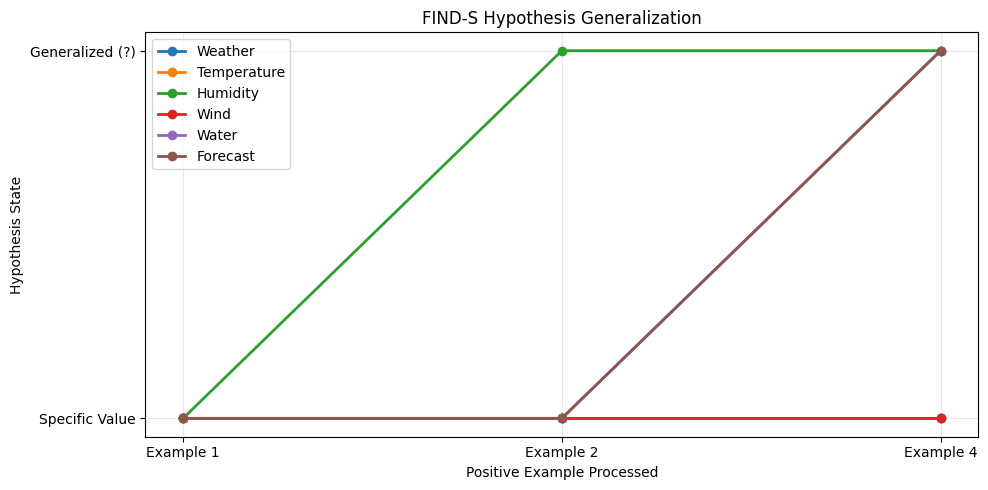

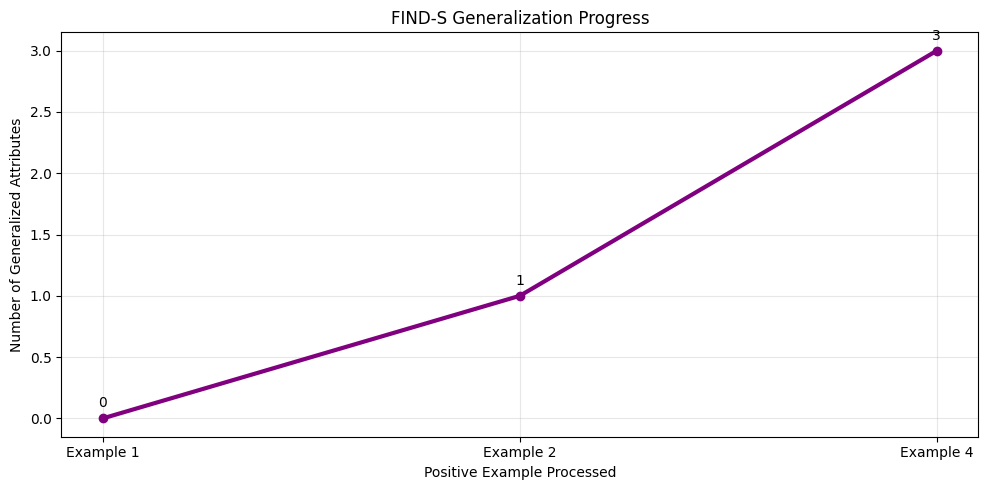

In [1]:
import matplotlib.pyplot as plt

# Training dataset
data = [
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
    ["Sunny", "Warm", "High", "Strong", "Warm", "Same", "Yes"],
    ["Rainy", "Cold", "High", "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High", "Strong", "Cool", "Change", "Yes"]
]

attributes = ["Weather", "Temperature", "Humidity",
              "Wind", "Water", "Forecast"]

# FIND-S algorithm
S = None
history = []
labels = []

for i, row in enumerate(data, start=1):
    x = row[:-1]
    target = row[-1]

    if target == "Yes":
        if S is None:
            S = x.copy()
        else:
            for j in range(len(S)):
                if S[j] != x[j]:
                    S[j] = "?"

        history.append(S.copy())
        labels.append("Example " + str(i))

print("Training Data:")
for row in data:
    print(row)

print("\nMost Specific Hypothesis:", S)

# Graph 1: Hypothesis Generalization
plt.figure(figsize=(10, 5))

for j, name in enumerate(attributes):
    y = [1 if h[j] == "?" else 0 for h in history]
    plt.plot(labels, y, marker="o", linewidth=2, label=name)

plt.yticks([0, 1], ["Specific Value", "Generalized (?)"])
plt.xlabel("Positive Example Processed")
plt.ylabel("Hypothesis State")
plt.title("FIND-S Hypothesis Generalization")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Generalization Progress
counts = [h.count("?") for h in history]

plt.figure(figsize=(10, 5))
plt.plot(labels, counts, marker="o",
         color="purple", linewidth=3)

for i, count in enumerate(counts):
    plt.annotate(str(count), (i, count),
                 textcoords="offset points",
                 xytext=(0, 8), ha="center")

plt.xlabel("Positive Example Processed")
plt.ylabel("Number of Generalized Attributes")
plt.title("FIND-S Generalization Progress")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
